# Stage 4 — Explanations, sanity checks and bias localisation

**4a (this part):** lung masks for every image, manual review of a sample, and the cascading
parameter-randomisation sanity check (Adebayo et al., 2018) for the attribution methods.

**Pre-registered rule for 4a.** A method is kept for Stage 4b only if, after randomising the
classifier and `denseblock4`, the mean Spearman correlation between its maps and the trained
model's maps falls below 0.5 and does not recover. A method that fails is reported but not
used to locate the bias.

All Stage 4 analyses use **validation** images. The test set is kept for the final table.

In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from src.data import REPO_ROOT
from src.dataset import CachedCXRDataset
from src.train import load_trained
from src.utils import get_device

DATA, CKPT, RESULTS = REPO_ROOT / "data", REPO_ROOT / "checkpoints", REPO_ROOT / "results"
FIG = REPO_ROOT / "docs" / "figures"
cache_path = DATA / "processed" / "images_224.npy"
mask_path = DATA / "processed" / "lung_masks_224.npy"
splits = pd.read_csv(DATA / "splits.csv")
device = get_device()
print(device)

mps


## 1. Lung masks

PSPNet from TorchXRayVision (trained on ChestX-Det). Each 224 px image is upsampled to the
512 px the segmenter expects and the union of both lungs is downsampled back to 224 px.
Stored once in `data/processed/lung_masks_224.npy` (not versioned). About 20–30 min on MPS;
the weights are downloaded on first use.

In [3]:
from src.masks import build_mask_cache

if not mask_path.exists():
    build_mask_cache(cache_path, mask_path, device)   # use torch.device("cpu") if MPS fails
stats = pd.read_csv(mask_path.with_suffix(".stats.csv"))
print(stats[["area_frac", "n_components", "largest_frac"]].describe().round(3))
print("suspect masks:", int(stats.suspect.sum()), f"({stats.suspect.mean():.1%})")

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/pspnet_chestxray_best_model_4.pth -O /Users/xabieralbizuarias/.torchxrayvision/models_data/pspnet_chestxray_best_model_4.pth`
[██████████████████████████████████████████████████]


Segmenting lungs: 100%|██████████| 1668/1668 [3:30:51<00:00,  7.58s/it]   

       area_frac  n_components  largest_frac
count  26679.000     26679.000     26679.000
mean       0.299         1.996         0.159
std        0.072         0.107         0.037
min        0.000         0.000         0.000
25%        0.252         2.000         0.135
50%        0.298         2.000         0.158
75%        0.346         2.000         0.182
max        0.597         3.000         0.365
suspect masks: 495 (1.9%)


### Manual review
40 random masks and up to 16 flagged as suspect (wrong number of components or extreme area).
Title = area fraction / number of components. **Write down below how many of the 40 are
acceptable and what goes wrong in the suspect ones.**

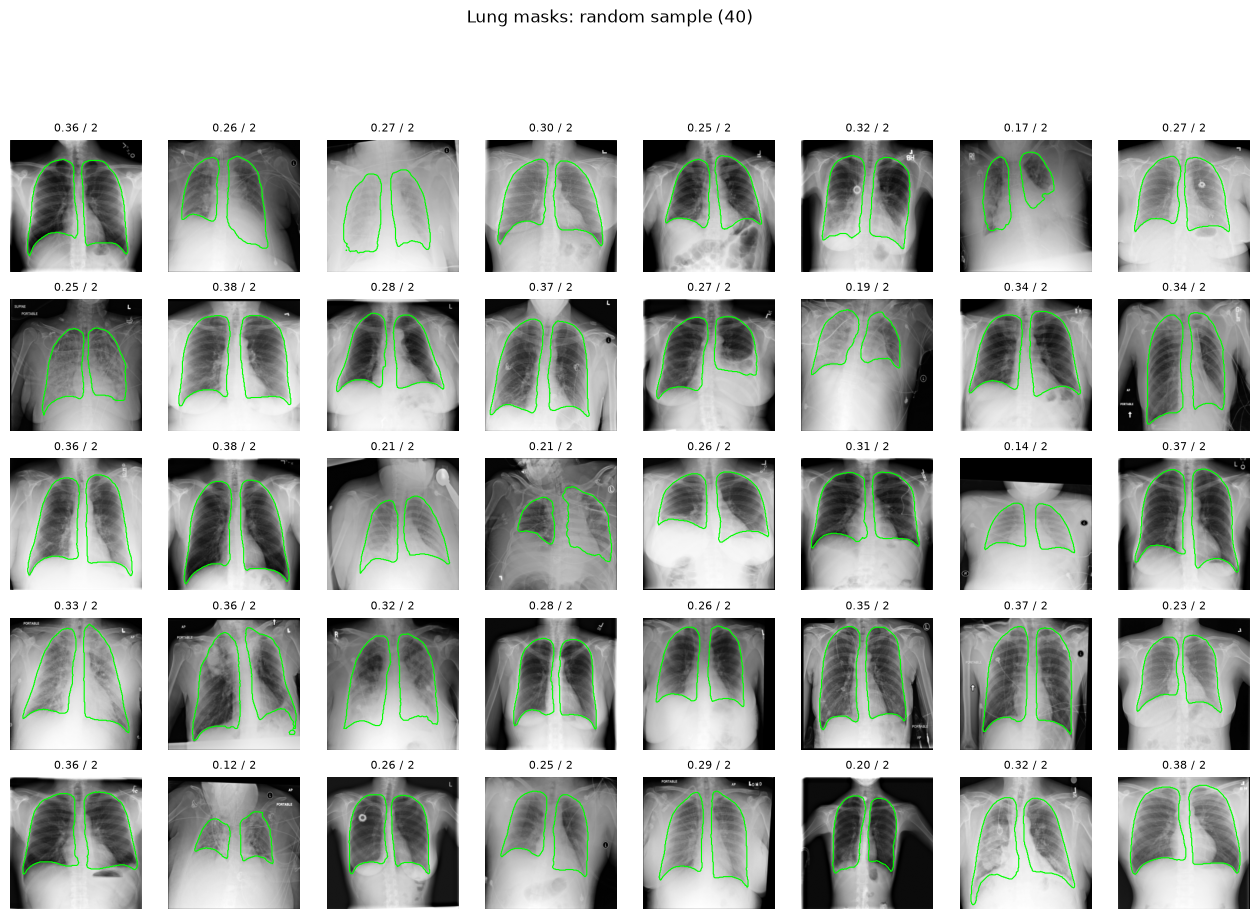

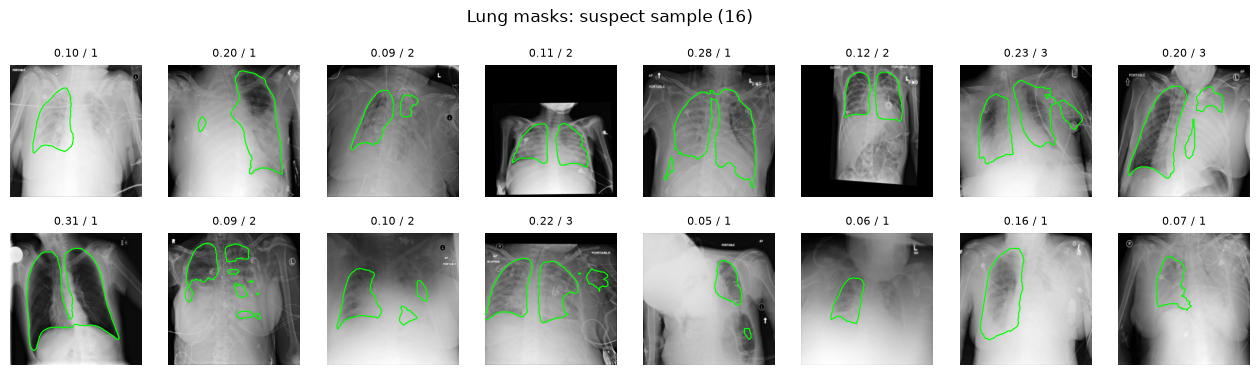

In [4]:
from src.viz import show_grid

images = np.load(cache_path, mmap_mode="r")
masks = np.load(mask_path, mmap_mode="r")
FIG.mkdir(parents=True, exist_ok=True)
for name, df in [("random", stats.sample(40, random_state=0)),
                 ("suspect", stats[stats.suspect].head(16))]:
    idx = df.index.to_numpy()
    fig = show_grid(images[idx], masks[idx],
                    titles=[f"{a:.2f} / {c}" for a, c in zip(df.area_frac, df.n_components)])
    fig.suptitle(f"Lung masks: {name} sample ({len(df)})", y=1.01)
    fig.savefig(FIG / f"masks_{name}.png", dpi=90, bbox_inches="tight")
    plt.show()

**Review notes.** ~37/40 random masks acceptable. Failures are under-segmentation of dense
consolidations (opaque lung tissue labelled as non-lung) and rotated or poorly exposed AP films.
Suspect masks (495, 1.9 %) are excluded from mask-based analyses. Mean lung area is smaller in
AP (0.28) than in PA (0.32), so the lung silhouette itself carries some view information.

### Does the mask itself carry view information?
Mask shape could correlate with the view (AP films are taken lying down). If the area
differs a lot between AP and PA, a lung-masked model (E2) could still read the view from the
mask outline. Recorded here as a caveat for Stage 5.

In [5]:
mask_view = stats.merge(splits[["patientId", "view", "target"]], on="patientId")
print(mask_view.groupby("view").area_frac.describe().round(3))
print(mask_view.groupby("view").suspect.mean().round(3))
mask_view.groupby("view").area_frac.describe().round(3).to_csv(RESULTS / "stage4_mask_area_by_view.csv")

        count   mean    std  min    25%    50%    75%    max
view                                                        
AP    12173.0  0.280  0.074  0.0  0.233  0.279  0.327  0.534
PA    14506.0  0.316  0.067  0.0  0.270  0.313  0.359  0.597
view
AP    0.035
PA    0.004
Name: suspect, dtype: float64


## 2. Sanity check: cascading parameter randomisation

200 validation images (50 per label × view). Layer groups of E1 (seed 0) are re-initialised
from the output towards the input, cumulatively; after each step the maps are compared with
the trained model's maps (Spearman on |map|, SSIM). `image_spearman` is the correlation of
the map with the input image itself: a method whose maps track the image more than the
model is acting as an edge detector. `auc` confirms the model is actually being destroyed.

In [6]:
from functools import partial
from src.explain import cam, integrated_gradients
from src.sanity import cascading_randomisation, CASCADE

val = splits[splits.split == "val"]
sample = pd.concat([d.sample(50, random_state=0) for _, d in val.groupby(["target", "view"])])
ds = CachedCXRDataset(cache_path, sample.patientId)
x = torch.stack([ds[i] for i in range(len(ds))]).to(device)
y = sample.target.to_numpy()

model = load_trained(CKPT / "e1_seed0.pt", device)
methods = {
    "Grad-CAM": partial(cam, method="gradcam"),
    "HiResCAM@db3": lambda m, xb: cam(m, xb, layer=m.features.denseblock3, method="hirescam"),
    "IG": partial(integrated_gradients, steps=16),
}
table, examples = cascading_randomisation(model, x, methods, y=y)
print(table.round(3).to_string(index=False))
table.to_csv(RESULTS / "stage4_sanity_randomisation.csv", index=False)

Randomising: 100%|██████████| 6/6 [08:39<00:00, 86.64s/it]

      method  step  randomised  spearman  ssim  image_spearman   auc
    Grad-CAM     0        none     1.000 1.000          -0.078 0.750
HiResCAM@db3     0        none     1.000 1.000          -0.132 0.750
          IG     0        none     1.000 1.000           0.310 0.750
    Grad-CAM     1  classifier    -0.198 0.175           0.036 0.487
HiResCAM@db3     1  classifier     0.069 0.360          -0.140 0.487
          IG     1  classifier     0.635 0.611           0.317 0.487
    Grad-CAM     2 denseblock4     0.090 0.276          -0.310 0.351
HiResCAM@db3     2 denseblock4    -0.255 0.140          -0.308 0.351
          IG     2 denseblock4     0.590 0.542           0.375 0.351
    Grad-CAM     3 denseblock3    -0.061 0.146          -0.031 0.440
HiResCAM@db3     3 denseblock3     0.107 0.378          -0.093 0.440
          IG     3 denseblock3     0.421 0.299           0.356 0.440
    Grad-CAM     4 denseblock2     0.161 0.348          -0.550 0.541
HiResCAM@db3     4 denseblock2    

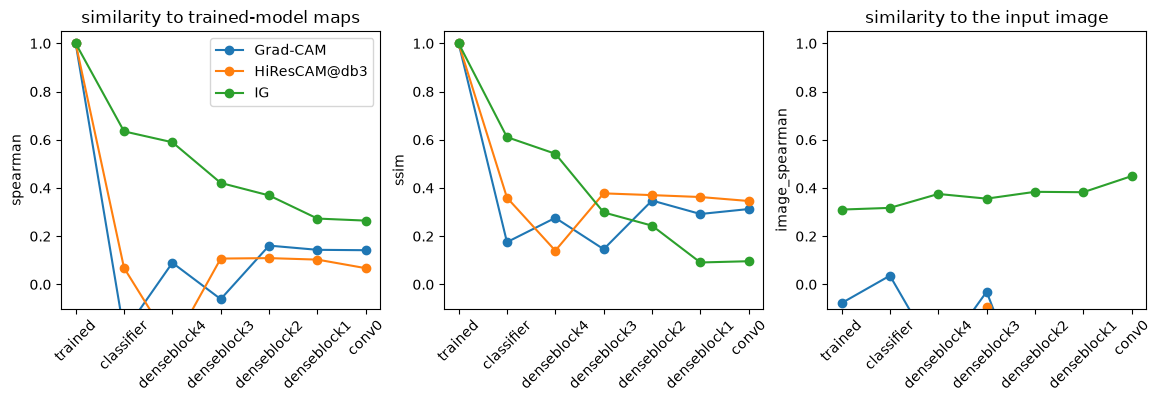

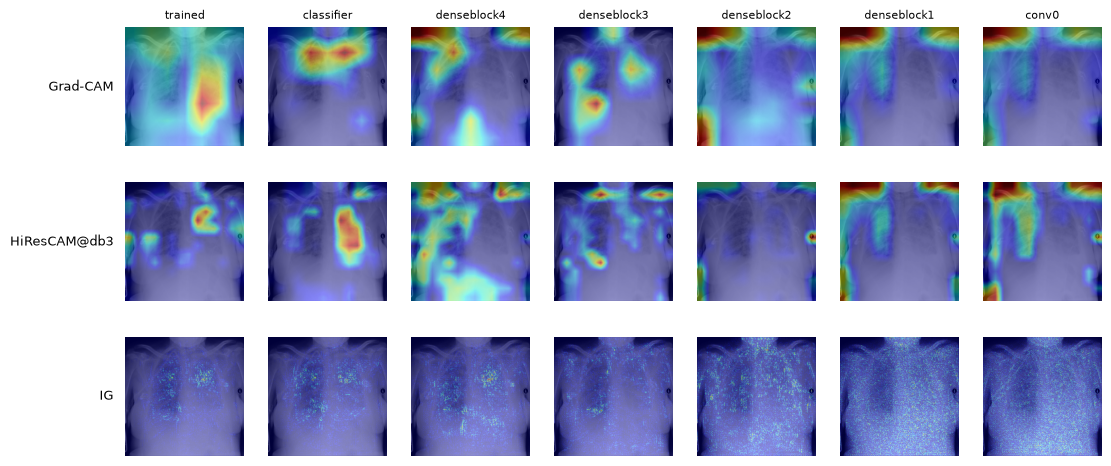

In [7]:
labels = ["trained"] + [c[0] for c in CASCADE]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, metric in zip(axes, ["spearman", "ssim", "image_spearman"]):
    for name, d in table.groupby("method", sort=False):
        ax.plot(d.step, d[metric], marker="o", label=name)
    ax.set(xticks=range(len(labels)), xticklabels=labels, ylabel=metric, ylim=(-0.1, 1.05))
    ax.tick_params(axis="x", rotation=45)
axes[0].set_title("similarity to trained-model maps")
axes[2].set_title("similarity to the input image")
axes[0].legend()
fig.savefig(FIG / "sanity_randomisation.png", dpi=150, bbox_inches="tight")
plt.show()

from src.viz import overlay
img = x[0, 0].cpu().numpy()
fig, axes = plt.subplots(len(methods), len(labels), figsize=(1.8 * len(labels), 1.9 * len(methods)))
for r, name in enumerate(methods):
    for c, m in enumerate(examples[name]):
        overlay(axes[r, c], img, heat=np.abs(m), title=labels[c] if r == 0 else None)
    axes[r, 0].text(-0.1, 0.5, name, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
fig.savefig(FIG / "sanity_randomisation_examples.png", dpi=120, bbox_inches="tight")
plt.show()

**Decision.** Methods that pass the rule: **Grad-CAM** (Spearman −0.20 after randomising the
classifier, 0.09 after denseblock4) and **HiResCAM@denseblock3** (0.07 and −0.25). Both stay
below 0.2 for the rest of the cascade, and their maps from the trained model are not correlated
with the input image (image Spearman −0.08 and −0.13).

Methods dropped: **Integrated Gradients**. Its maps keep a Spearman of 0.63 after randomising the
classifier and 0.59 after denseblock4, above the 0.5 threshold, and their correlation with the
input image stays at 0.31–0.45 whatever the weights. It behaves partly as an edge detector, as
reported by Adebayo et al. (2018), so it is not used to locate the bias.

Control: the model AUC on these 200 images falls from 0.75 to about 0.5 after the first steps,
confirming that the randomisation destroys the model. SSIM of the CAM maps stays around 0.3 even
for the destroyed model because CAMs are smooth blobs; Spearman is therefore the deciding metric.